# TRUSTSR Lab 03.05 — Parameterized Retry Stress Test

**Phase:** Lab 03 — Reliability and evidence integrity  
**Status:** Synthetic simulation | Version 0.1.0

## Motivation
Lab 03.04 tested four fixed event scenarios. This lab scales the experiment across many synthetic events and retry limits to quantify how retry policy changes delivery outcomes under a defined failure model.

## Model and metrics
- Each logical event has one stable unique ID.
- Each attempt independently experiences a pre-storage transient failure with configured probability `p`.
- If an attempt does not fail before storage, the receiver accepts it; a later retry after an ambiguous timeout is not modeled in this experiment.
- Events are retried up to `max_attempts`.
- **Delivery success rate** = events stored / intended events.
- **Missing-event rate** = intended events absent at receiver / intended events.
- **Mean attempts** = total attempts / intended events.
- Random seed is fixed for reproducibility of this run; results may change with seed, event count, and model assumptions.

**Evidence boundary:** all outputs are synthetic simulation, not measurements of a real network, logging service, or production agent.

## 1. Configure experiment

In [1]:
import random, json, sqlite3, tempfile, os, hashlib, sys
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261011
N_EVENTS = 2000
FAILURE_PROBABILITIES = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]
RETRY_LIMITS = [1, 2, 3, 5, 8]
rng = random.Random(SEED)

print("Python:", sys.version.split()[0])
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print(f"Synthetic simulation: seed={SEED}, events per condition={N_EVENTS}")
print("Failure probabilities:", FAILURE_PROBABILITIES)
print("Retry limits:", RETRY_LIMITS)

Python: 3.12.3
Execution UTC: 2026-10-11T10:26:35.175789+00:00
Synthetic simulation: seed=20261011, events per condition=2000
Failure probabilities: [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]
Retry limits: [1, 2, 3, 5, 8]


## 2. Run parameterized simulation

In [2]:
def run_condition(n_events, p_fail, max_attempts, rng):
    delivered = 0
    total_attempts = 0
    per_event = []
    for i in range(n_events):
        event_id = f"p{p_fail:.1f}_r{max_attempts}_event_{i:05d}"
        stored = False
        attempts = 0
        for attempt in range(1, max_attempts + 1):
            attempts += 1
            total_attempts += 1
            # Synthetic transient failure before storage.
            if rng.random() >= p_fail:
                stored = True
                delivered += 1
                break
        per_event.append({"event_id":event_id, "p_fail":p_fail, "retry_limit":max_attempts,
                          "attempts":attempts, "stored":stored})
    missing = n_events - delivered
    return {
        "p_fail":p_fail, "retry_limit":max_attempts, "intended_events":n_events,
        "delivered_events":delivered, "missing_events":missing,
        "delivery_success_rate":delivered/n_events,
        "missing_event_rate":missing/n_events,
        "mean_attempts_per_event":total_attempts/n_events,
        "attempts_total":total_attempts
    }, per_event

summary_rows, event_rows = [], []
for p_fail in FAILURE_PROBABILITIES:
    for retry_limit in RETRY_LIMITS:
        summary, events = run_condition(N_EVENTS, p_fail, retry_limit, rng)
        summary_rows.append(summary)
        event_rows.extend(events)

summary_df = pd.DataFrame(summary_rows)
event_df = pd.DataFrame(event_rows)
display(summary_df.head(10))
print("Conditions executed:", len(summary_df), "| Synthetic event records:", len(event_df))
assert len(summary_df) == len(FAILURE_PROBABILITIES) * len(RETRY_LIMITS)
assert len(event_df) == N_EVENTS * len(summary_df)
assert summary_df["delivery_success_rate"].between(0,1).all()
assert summary_df["missing_event_rate"].between(0,1).all()
assert (summary_df["delivered_events"] + summary_df["missing_events"] == N_EVENTS).all()
print("Simulation structure assertions passed.")

   p_fail  retry_limit  intended_events  delivered_events  missing_events  delivery_success_rate  missing_event_rate  mean_attempts_per_event  attempts_total
0     0.0            1             2000              2000               0                 1.0000              0.0000                   1.0000            2000
1     0.0            2             2000              2000               0                 1.0000              0.0000                   1.0000            2000
2     0.0            3             2000              2000               0                 1.0000              0.0000                   1.0000            2000
3     0.0            5             2000              2000               0                 1.0000              0.0000                   1.0000            2000
4     0.0            8             2000              2000               0                 1.0000              0.0000                   1.0000            2000
5     0.1            1             2000             

Conditions executed: 30 | Synthetic event records: 60000
Simulation structure assertions passed.


## 3. Plot success and missing-event rates

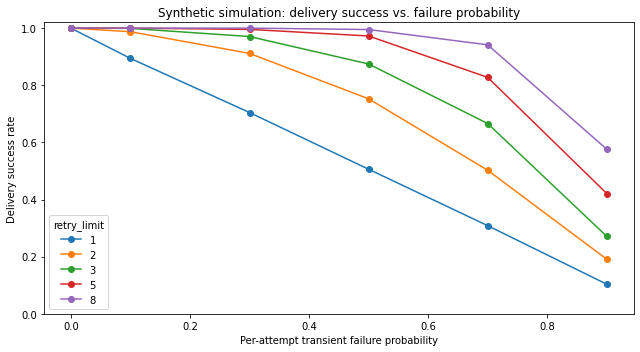

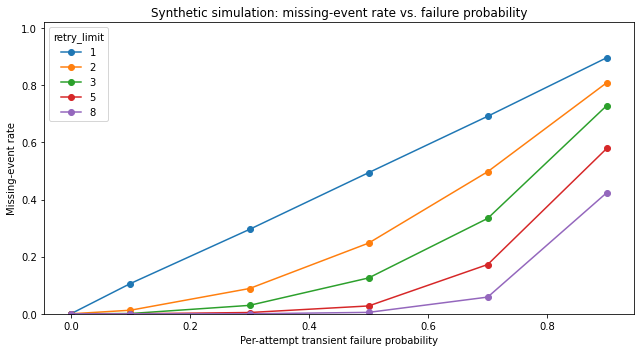

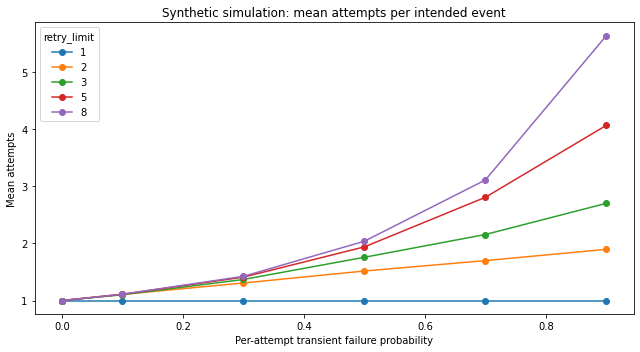

In [3]:
pivot_success = summary_df.pivot(index="p_fail", columns="retry_limit", values="delivery_success_rate")
ax = pivot_success.plot(marker="o", figsize=(9,5))
ax.set_title("Synthetic simulation: delivery success vs. failure probability")
ax.set_xlabel("Per-attempt transient failure probability")
ax.set_ylabel("Delivery success rate")
ax.set_ylim(0,1.02)
plt.tight_layout()
plt.show()

pivot_missing = summary_df.pivot(index="p_fail", columns="retry_limit", values="missing_event_rate")
ax = pivot_missing.plot(marker="o", figsize=(9,5))
ax.set_title("Synthetic simulation: missing-event rate vs. failure probability")
ax.set_xlabel("Per-attempt transient failure probability")
ax.set_ylabel("Missing-event rate")
ax.set_ylim(0,1.02)
plt.tight_layout()
plt.show()

pivot_attempts = summary_df.pivot(index="p_fail", columns="retry_limit", values="mean_attempts_per_event")
ax = pivot_attempts.plot(marker="o", figsize=(9,5))
ax.set_title("Synthetic simulation: mean attempts per intended event")
ax.set_xlabel("Per-attempt transient failure probability")
ax.set_ylabel("Mean attempts")
plt.tight_layout()
plt.show()

## 4. Compare retry limits and validate monotonic expectations

In [4]:
# For a fixed failure probability and this model, increasing the retry limit should not lower delivery success.
monotonic_rows = []
for p_fail, group in summary_df.groupby("p_fail"):
    ordered = group.sort_values("retry_limit")
    rates = ordered["delivery_success_rate"].tolist()
    monotonic = all(a <= b for a,b in zip(rates, rates[1:]))
    monotonic_rows.append({"p_fail":p_fail,"success_non_decreasing_with_retries":monotonic,
                           "min_success":min(rates),"max_success":max(rates)})
monotonic_df = pd.DataFrame(monotonic_rows)
display(monotonic_df)
assert monotonic_df["success_non_decreasing_with_retries"].all()

# With p_fail=0, all events should be delivered on first attempt.
zero_failure = summary_df[summary_df["p_fail"]==0.0]
assert (zero_failure["delivery_success_rate"] == 1.0).all()
assert (zero_failure["mean_attempts_per_event"] == 1.0).all()

# For p_fail=0.9 and one attempt, success rate should be close to 0.1 within a broad finite-sample tolerance.
high_failure_one_retry = summary_df[(summary_df["p_fail"]==0.9)&(summary_df["retry_limit"]==1)].iloc[0]
assert abs(high_failure_one_retry["delivery_success_rate"] - 0.1) < 0.06
print("Policy assertions passed. These assertions test the synthetic model, not a real system.")

   p_fail  success_non_decreasing_with_retries  min_success  max_success
0     0.0                                 True       1.0000       1.0000
1     0.1                                 True       0.8940       1.0000
2     0.3                                 True       0.7045       1.0000
3     0.5                                 True       0.5060       0.9950
4     0.7                                 True       0.3085       0.9415
5     0.9                                 True       0.1035       0.5760

Policy assertions passed. These assertions test the synthetic model, not a real system.


## 5. Export CSV evidence artifacts

In [5]:
summary_df.to_csv("trustsr_lab03_05_retry_stress_summary.csv", index=False)
event_df.to_csv("trustsr_lab03_05_retry_stress_event_level.csv", index=False)
monotonic_df.to_csv("trustsr_lab03_05_retry_monotonic_checks.csv", index=False)
print("CSV exports created:")
print("- trustsr_lab03_05_retry_stress_summary.csv")
print("- trustsr_lab03_05_retry_stress_event_level.csv")
print("- trustsr_lab03_05_retry_monotonic_checks.csv")
print("Classification: synthetic simulation only.")

CSV exports created:
- trustsr_lab03_05_retry_stress_summary.csv
- trustsr_lab03_05_retry_stress_event_level.csv
- trustsr_lab03_05_retry_monotonic_checks.csv
Classification: synthetic simulation only.


## 6. Interpretation and limitations

### What this experiment can support
It can show how delivery success, missing-event rate, and attempt count change **within this defined synthetic failure model** as retry limits and injected transient-failure probabilities vary.

### What it cannot support
- It does not show performance or reliability of a real network or logging service.
- It does not model timeout-after-store ambiguity, duplicate delivery, correlated outages, backoff, rate limits, concurrency, or receiver restarts.
- A fixed random seed makes this run reproducible, but not representative of real operational conditions.
- The failure probability is an input assumption, not an empirically estimated rate.

### Next engineering step
Extend the model to correlated outage windows and ambiguous timeout-after-store behavior, then compare with a remote receiver under controlled fault injection before making real-world reliability claims.